<a href="https://colab.research.google.com/github/laoneya31/IAT360-Group-18/blob/main/notebooks/Philip_Dataset_LearningRate_FinalModel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<center><h1><b>Dataset Build, Learning Rate and Final Model</b></h1></center>
<center>IAT 360 Group 18 (Philip)</center>

**Tasks:** build the YOLO dataset, tune `lr0`, combine the best values into the final model.

**Hand-off:** the team is blocked on this. Upload `fruit_freshness.zip` to `IAT360-Group 18/dataset/` and everyone's notebook picks it up automatically.

# 1. Environment

Use a GPU runtime: **Runtime > Change runtime type > T4 GPU**. The shared Drive folder must be in your My Drive: right-click `IAT360-Group 18` in *Shared with me* and choose **Organize > Add shortcut**.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Clone our repo and the official YOLO repo. YOLO is pinned to one release so all four members train with identical code.

In [2]:
import os, sys
REPO = "/content/IAT360-Group-18"
YOLO_TAG = "v8.4.204"

if os.path.exists(REPO):
    !git -C {REPO} pull --ff-only
else:
    !git clone https://github.com/laoneya31/IAT360-Group-18 {REPO}
# The folder must not be called "ultralytics": /content is on sys.path, so it would hide the real package.
if not os.path.exists("/content/yolo_repo"):
    !git -c advice.detachedHead=false clone -q --depth 1 --branch {YOLO_TAG} https://github.com/ultralytics/ultralytics /content/yolo_repo
%pip install -q /content/yolo_repo kagglehub
%cd {REPO}

remote: Enumerating objects: 4, done.
remote: Counting objects: 100% (4/4), done.
remote: Compressing objects: 100% (4/4), done.
remote: Total 4 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Unpacking objects: 100% (4/4), 666.86 KiB | 1.40 MiB/s, done.
From https://github.com/laoneya31/IAT360-Group-18
   2e56514..c049d3b  main       -> origin/main
Updating 2e56514..c049d3b
Fast-forward
 .../Jasper_Annotation_ImageSize_Augmentation.ipynb | 3389 ++++++++++++++++++--
 1 file changed, 3207 insertions(+), 182 deletions(-)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
/content/IAT360-Group-18


Importing required libraries, and checking the software and hardware.

In [3]:
import glob, hashlib, random, shutil
import cv2
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image

import ultralytics
ultralytics.checks()
from ultralytics import YOLO

sys.path.insert(0, f"{REPO}/src")
import fruit_yolo as fy

fy.check_config()
print("Team Drive folder:", fy.find_team_drive())
print("Baseline settings:", fy.BASELINE)

Ultralytics 8.4.204 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 1.4/112.6 GB disk)
config.yaml: 6 classes, order matches.
Team Drive folder: /content/drive/MyDrive/IAT360-Group 18
Baseline settings: {'model': 'yolov8s.pt', 'epochs': 50, 'patience': 20, 'imgsz': 640, 'batch': 16, 'optimizer': 'AdamW', 'lr0': 0.001, 'momentum': 0.9, 'warmup_bias_lr': 0.0, 'seed': 0, 'deterministic': True}


## 2. Build the dataset

Required layout (same as the course tutorial, and already in the repo):

```
datasets/fruit_freshness/
  images/train  images/val  images/test
  labels/train  labels/val  labels/test
```

**Things to watch for, found while testing the pipeline:**
- The Kaggle freshness download has a full second copy in `dataset/dataset/`. Use only `dataset/train` and `dataset/test`, never a recursive search.
- Its photos are pre-augmented screenshots (rotations of the same fruit), so split by source image before making composites. `build_composites` does this for one source folder.
- The Roboflow export may spell classes `rotton_*`. Ids still line up if the order is unchanged; `fy.check_config` confirms it.
- Use bounding-box export, not polygons.

In [4]:
import glob, kagglehub, shutil
import xml.etree.ElementTree as ET

freshness = kagglehub.dataset_download("sriramr/fruits-fresh-and-rotten-for-classification")
detection = kagglehub.dataset_download("mbkinaci/fruit-images-for-object-detection")
print(freshness, detection)

Using Colab cache for faster access to the 'fruits-fresh-and-rotten-for-classification' dataset.


100%|██████████| 28.4M/28.4M [00:00<00:00, 85.9MB/s]

Extracting files...


/kaggle/input/fruits-fresh-and-rotten-for-classification /root/.cache/kagglehub/datasets/mbkinaci/fruit-images-for-object-detection/versions/1


### Roboflow dataset

Add your API key in Colab's **Secrets** panel (key icon) as `ROBOFLOW_API_KEY`. Do not paste it in a cell, this repo is public.

In [ ]:
# TODO: fill in the version number, then convert its labels to our six classes.
# %pip install -q roboflow
# from google.colab import userdata
# from roboflow import Roboflow
# rf = Roboflow(api_key=userdata.get("ROBOFLOW_API_KEY"))
# rf.workspace("ai-project-t3iak").project("detection-of-rotten-fruits").version(1).download("yolov8", location="/content/roboflow")

### Kaggle detection set: XML to YOLO

These boxes say `apple`, `banana` or `orange` with no freshness, so each box needs a freshness decision using the labelling rules. `FRESHNESS` is a starting assumption only.

In [5]:
FRESHNESS = {"apple": 0, "banana": 1, "orange": 2}   # TODO: review images and relabel rotten ones to 3, 4, 5

def voc_to_yolo(xml_path):
    root = ET.parse(xml_path).getroot()
    width, height = int(root.find("size/width").text), int(root.find("size/height").text)
    if not width or not height:
        return None  # some files in this dataset have size 0: read the size from the image instead
    rows = []
    for obj in root.iter("object"):
        box = obj.find("bndbox")
        x1, y1, x2, y2 = (float(box.find(k).text) for k in ("xmin", "ymin", "xmax", "ymax"))
        rows.append(f"{FRESHNESS[obj.find('name').text]} {(x1 + x2) / 2 / width:.6f} {(y1 + y2) / 2 / height:.6f} "
                    f"{(x2 - x1) / width:.6f} {(y2 - y1) / height:.6f}")
    return rows

# TODO: loop over the XML files and write images and .txt labels into fy.DATASET.

### Composite scenes

In [6]:
folders = ["freshapples", "freshbanana", "freshoranges", "rottenapples", "rottenbanana", "rottenoranges"]
sources = {i: glob.glob(f"{freshness}/dataset/train/{name}/*") for i, name in enumerate(folders)}
# TODO: choose the counts. Composites go in train and val only: test is our own 120 photos.
# fy.build_composites(sources, fy.DATASET, {"train": 3000, "val": 600}, seed=0)

### Our own 120 photos

Copy all members' exported images and labels into `images/test` and `labels/test`. Faces blurred first. Export from Roboflow with auto-orient on, so EXIF rotation is already applied: `validate_dataset` warns if it is not.

In [ ]:
# TODO: copy the four members' Roboflow exports here.

### Validate and share

In [7]:
report = fy.validate_dataset()
fy.assert_valid(report)

KeyboardInterrupt: 

In [ ]:
# Stops if the dataset is empty or invalid, so it cannot overwrite a good zip on Drive.
fy.share_dataset()

## Hyperparameter tuning

`lr0`, baseline 0.001. This only has an effect because `BASELINE` sets the optimizer explicitly. In a 15-epoch practice run, `lr0=0.01` collapsed training with AdamW (mAP@0.5:0.95 of 0.07 against 0.80 at 0.001), so consider a lower third value such as 0.002. Tell the group if you change it.

Only this one value changes. Everything else stays at the shared baseline, so the difference from the baseline can be attributed to it.

In [8]:
assert fy.fetch_dataset(), "Dataset is not on Drive yet."
OWNER = "Philip"
PARAM, VALUES = fy.TUNING_PLAN[OWNER]
RUNS = [f"{PARAM}_{v}" for v in VALUES]

for name, value in zip(RUNS, VALUES):
    weights = fy.train_run(name, OWNER, overrides={PARAM: value})
    fy.evaluate(name, weights)

Dataset up to date: /content/IAT360-Group-18/datasets/fruit_freshness
GPU: Tesla T4
config.yaml: 6 classes, order matches.
lr0_0.0003: already trained, using /content/drive/MyDrive/IAT360-Group 18/results/weights/lr0_0.0003.pt


KeyboardInterrupt: 

,owner,changed,accuracy,precision,recall,f1,mAP50,mAP50_95,rotten_recall,rotten_flag_recall,minutes,effective_batch,mAP50_95_vs_baseline
run,,,,,,,,,,,,,
baseline,Daksh,none,0.8661,0.9296,0.9467,0.9381,0.9726,0.8341,0.9257,0.9500,41.1,64,0.0000
lr0_0.0003,Philip,lr0=0.0003,0.9072,0.9651,0.9644,0.9648,0.9805,0.8434,0.9434,0.9542,38.3,64,0.0093
lr0_0.003,Philip,lr0=0.003,0.8187,0.9168,0.9219,0.9193,0.9722,0.8098,0.9091,0.9583,39.5,64,-0.0243
lr0_0.01,Philip,lr0=0.01,0.7743,0.9103,0.8990,0.9046,0.9585,0.7823,0.8960,0.9625,40.0,64,-0.0519


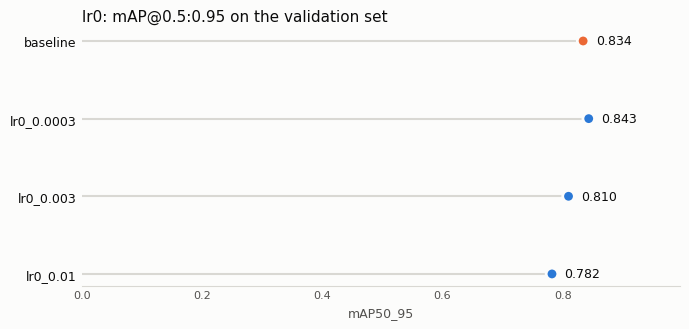

lr0_0.0003 {'epochs_run': 50, 'best_epoch': 47, 'final_train_loss': 0.5531, 'final_val_loss': 0.8904, 'lowest_val_loss': 0.8772, 'val_loss_rise_after_best': 0.0132, 'train_val_gap': 0.3373, 'reading': 'val loss flattened with train loss: reasonable fit'}
lr0_0.003 {'epochs_run': 50, 'best_epoch': 48, 'final_train_loss': 0.7505, 'final_val_loss': 1.0514, 'lowest_val_loss': 1.0391, 'val_loss_rise_after_best': 0.0123, 'train_val_gap': 0.3008, 'reading': 'val loss flattened with train loss: reasonable fit'}
lr0_0.01 {'epochs_run': 50, 'best_epoch': 50, 'final_train_loss': 0.8737, 'final_val_loss': 1.1395, 'lowest_val_loss': 1.1395, 'val_loss_rise_after_best': 0.0, 'train_val_gap': 0.2658, 'reading': 'val loss still falling at the end: likely underfit, train longer'}


In [9]:
table = fy.compare_runs(names=["baseline"] + RUNS)
display(table)
fy.plot_comparison(table, f"{PARAM}: mAP@0.5:0.95 on the validation set",
                   save_to=fy.output_root() / "figures" / f"tuning_{PARAM}.png")
plt.show()
for name in RUNS:
    print(name, fy.fit_report(name))

### My results

*TODO: which value won, by how much, and why you think that happened. Copy this into the report.*

Make a zip of your runs for GitHub: unzip it at the top of the repo and commit.

In [ ]:
fy.package_results(RUNS)

## Final model

Combine the best value from each member, retrain, and evaluate. Pick values from the group's comparison, not only the single highest number.

In [10]:
best = {"lr0": None, "imgsz": None, "batch": None, "freeze": None}   # TODO: fill in; delete any that did not beat the baseline
best = {k: v for k, v in best.items() if v is not None}
final_weights = fy.train_run("final", "Philip", overrides=best)
final = fy.evaluate("final", final_weights)
display(fy.compare_runs(names=["baseline", "final"]))

GPU: Tesla T4
config.yaml: 6 classes, order matches.
New https://pypi.org/project/ultralytics/8.4.208 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.204 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/IAT360-Group-18/config.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.0003, lrf=0.01, mask_ratio=4, m

,owner,changed,accuracy,precision,recall,f1,mAP50,mAP50_95,rotten_recall,rotten_flag_recall,minutes,effective_batch,mAP50_95_vs_baseline
run,,,,,,,,,,,,,
baseline,Daksh,none,0.8661,0.9296,0.9467,0.9381,0.9726,0.8341,0.9257,0.9500,41.1,64,0.0000
final,Philip,lr0=0.0003,0.9072,0.9651,0.9644,0.9648,0.9805,0.8434,0.9434,0.9542,40.0,64,0.0093


In [11]:
fy.package_results(["final"])

Unzip at the top of the repo, then commit: /content/drive/MyDrive/IAT360-Group 18/results/results_for_github.zip


'/content/drive/MyDrive/IAT360-Group 18/results/results_for_github.zip'